In [2]:
# Task: Geospatial Analysis

# Visualize the locations of restaurants on a map using latitude and longitude information.
# Analyze the distribution of restaurants across different cities or countries.
# Determine if there is any correlation between the restaurant's location and its rating.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from folium.plugins import HeatMap

# Load Dataset
data = pd.read_csv("/home/vansh-kumar/cognifyz Task/Dataset .csv")
# data

print("\nDataset Shape:", data.shape)
print("\nAvailable Columns:")
print(data.columns.tolist())


Dataset Shape: (9551, 21)

Available Columns:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']


In [4]:
# Check Required Columns

required = ["Latitude", "Longitude"]

missing = [col for col in required if col not in data.columns]

if missing:
    raise ValueError(F"Missing Columns: {missing}."
                     "Check the latitude and longitude columns names.")
    
# Convert coordinates and rating to numeric values
data["Latitude"] = pd.to_numeric(data["Latitude"], errors="coerce")
data["Latitude"] = pd.to_numeric(data["Longitude"], errors="coerce")

if "Aggrigate rating" in data.columns:
    data["Aggregate rating"] = pd.to_numeric(data["Aggregate rating"], errors="coerce")

# Remove missing or invalid geographical coordinates
geographical = data.dropna(subset=["Latitude", "Longitude"]).copy()

geographical = geographical[geographical["Latitude"].between(-90,90) & geographical["Longitude"].between(-180,180)]

print("\nRestaurants with valid coordinates:", len(geographical))
print("Rows exclude due to invalild coordinates:", len(data) - len(geographical))

if geographical.empty:
    raise ValueError("No valid geographical coordinates were found.")


Restaurants with valid coordinates: 9218
Rows exclude due to invalild coordinates: 333


In [5]:
# Create Interactive Restaurant Map

import folium

centre = [geographical["Latitude"].median(), geographical["Longitude"].median()]

restaurant_map = folium.Map(location = centre,zoom_start = 5,control_scale = True)

# Limit markers to keep the map responsive
map_data = geographical.sample(n=min(3000, len(geographical)),random_state=42)

for _, row in map_data.iterrows():
    restaurant_name = str(row.get("Restaurant Name", "Restaurant"))
    
    popup_text = restaurant_name
    
    if "City" in geographical.columns and pd.notna(row.get("City")):
        popup_text += f" | City: {row['City']}"
        
    if "Aggregate rating" in geographical.columns:
        rating = row.get("Aggregate rating")
        if pd.notna(rating):
            popup_text += f" | Rating: {rating}"
            
    folium.CircleMarker(location=[row["Latitude"], row["Longitude"]],
                        radius=3, popup=popup_text,fill= True, fill_opacity = 0.6).add_to(restaurant_map)

restaurant_map.save("task3_restaurant_map")

In [6]:
#  create Restaurent Density Heatmap

import folium

heat_map = folium.Map(location=centre, zoom_start=5, control_scale=True)

heat_points = geographical[["Latitude", "Longitude"]].sample(
    n=min(10000, len(geographical)),random_state=42).values.tolist()

HeatMap(heat_points,radius=10,blur=8).add_to(heat_map)
restaurant_map.save("task3_restaurant_heatmap")



Top 10 cities by restaurants listings:
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21


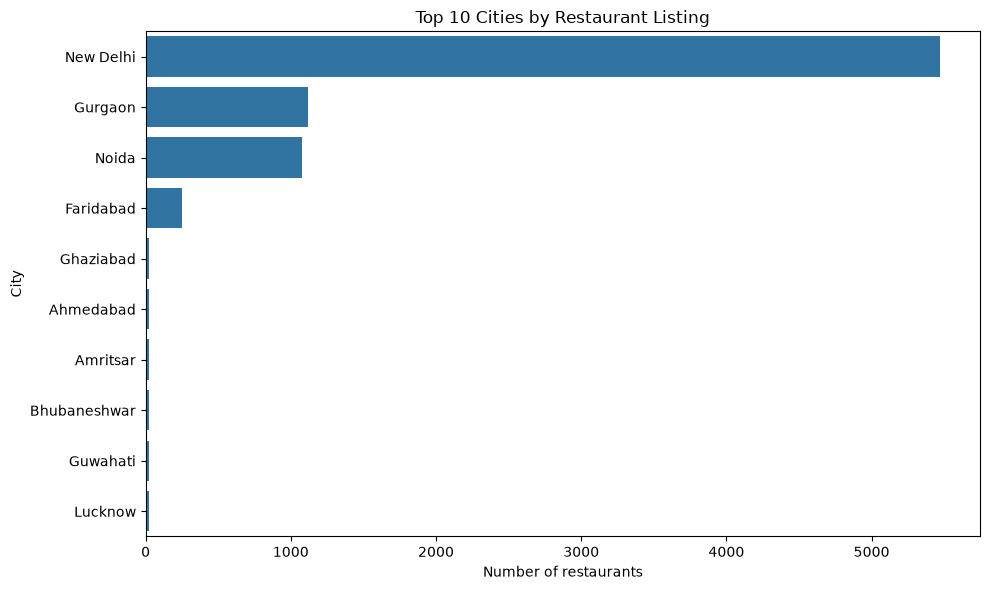

In [7]:
#  Restaurants Distribution By City

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



data = pd.read_csv("/home/vansh-kumar/cognifyz Task/Dataset .csv")
if "City" in data.columns:
    city_counts = data["City"].dropna().value_counts().head(10)
    
    print("\nTop 10 cities by restaurants listings:")
    print(city_counts.to_string())
    
    plt.figure(figsize=(10,6))
    sns.barplot(x=city_counts.values, y=city_counts.index)
    plt.title("Top 10 Cities by Restaurant Listing")
    plt.xlabel("Number of restaurants")
    plt.ylabel("City")
    plt.tight_layout()
    plt.show()


Top 10 Country Codes by restaurant listing:
Country Code
1      8652
216     434
215      80
30       60
214      60
189      60
148      40
208      34
14       24
162      22


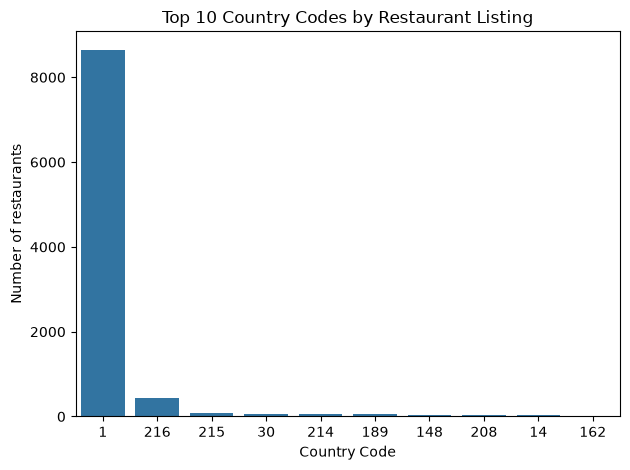

In [8]:
# Restaurants Distribution By Country

if "Country Code" in data.columns:
    country_counts = data["Country Code"].value_counts().head(10)
    
    print("\nTop 10 Country Codes by restaurant listing:")
    print(country_counts.to_string())
    
    plt.Figure(figsize=(9,5))
    sns.barplot(x=country_counts.index.astype(str), y=country_counts.values)
    plt.title("Top 10 Country Codes by Restaurant Listing")
    plt.xlabel("Country Code")
    plt.ylabel("Number of restaurants")
    plt.tight_layout()
    plt.show()


Restaurants with positive ratings and valid coordinates: 7073

Corrleation of coordinates with rating:
Latitude    -0.319
Longitude   -0.319
Name: Aggregate rating, dtype: float64

Top 10 cities by average rating
                Average_Rating  Restaurant_Count
City                                            
London                   4.535                20
Rio de Janeiro           4.489                19
Orlando                  4.475                20
Tampa Bay                4.410                20
Bangalore                4.375                20
Dubai                    4.370                20
Hyderabad                4.344                18
Chennai                  4.315                20
Ankara                   4.305                20
Sandton                  4.300                11


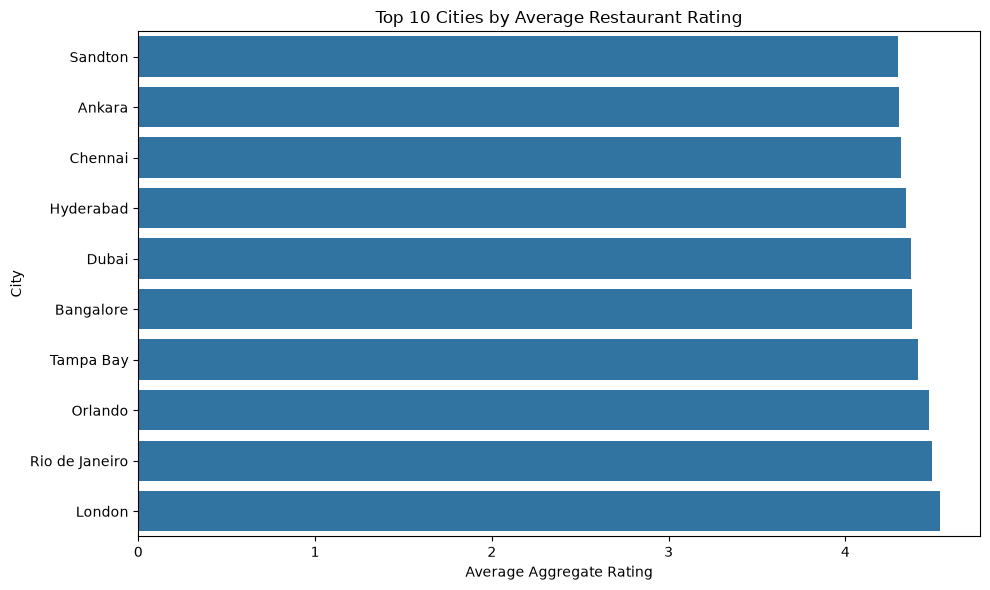

In [12]:
# Location And Restaurant Ratings

if "Aggregate rating" in data.columns:
    rated = geographical[geographical["Aggregate rating"].gt(0)].copy()
    
    print("\nRestaurants with positive ratings and valid coordinates:",len(rated))
    
    # correlation between rating and coordinates
    if len(rated) >= 2:
        correlation = rated[["Aggregate rating", "Latitude","Longitude"]].corr(numeric_only=True)["Aggregate rating"]
        
        print("\nCorrleation of coordinates with rating:")
        print(correlation.drop("Aggregate rating").round(3))
        
    # Average rating by city;
    if "City" in rated.columns:
        city_rating = rated.groupby("City")["Aggregate rating"].agg(Average_Rating='mean',Restaurant_Count="count")
        
        city_rating = city_rating[
            city_rating["Restaurant_Count"] >= 10
        ].sort_values("Average_Rating", ascending=False)
        
        print("\nTop 10 cities by average rating")
        print(city_rating.head(10).round(3).to_string())
        
        plot_data = city_rating.head(10).sort_values("Average_Rating")
        
        if not plot_data.empty:
            plt.figure(figsize=(10,6))
            sns.barplot(x=plot_data["Average_Rating"],y=plot_data.index)
            plt.title("Top 10 Cities by Average Restaurant Rating")
            plt.xlabel("Average Aggregate Rating")
            plt.ylabel("City")
            plt.tight_layout()
            plt.show()